<a href="https://colab.research.google.com/github/fluids/AI4GSD/blob/main/Demo_Colab/Demo7_Run_On_Your_Folder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI4GSD Demo
------------------------------------------
## Drone Videos
------------------------------------------
#### Table of contents
#### 0. Installing requried packages
#### 1. Importing required packages
#### 2. Defining working directory
#### 3. Extracting or copying your videos/photos to desired folder
#### 4. Obtaining scales from AI, drone flight data, or manual measurements
#### 5. Obtaining segmentation of anthropogenic objects
#### 6. Obtaining grain size data
#### 7. Applying quality control
#### 8. Data visualization

##### *** Please contact Yunxiang Chen, yunxiang.chen@pnnl.gov for reporting errors

------------------------------------------
### 0. Installing requried packages

#### 0a. Install requried packages

In [ ]:
%pip install -q ultralytics==8.3.186 natsort pyproj PyExifTool piexif imutils shapely psutil gdown

#### 0b. Connect Google drive to Colab runtime.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#### 0c. Create AI4GSD parent direcotry and download source codes if not found.

In [ ]:
import sys, subprocess
from pathlib import Path
WorkDir = Path("/content/drive/MyDrive/AI4GSD")
sys.path.insert(0,str(WorkDir))
if not WorkDir.exists():subprocess.run(["git", "clone", "--progress","https://github.com/pnnl/AI4GSD.git", str(WorkDir)],check=True)

### 1. Importing required packages

In [ ]:
import AI4GSD

### 2. Defining working directory

In [ ]:
AI4GSD.pcinfo()
DriveDir = Path("/content/drive/MyDrive")
foldername = '20261113_YC_CSF'                                             # Parent folder where you save photos/videos.
PhotoDir = str(DriveDir / foldername)                                       # AI4GSD use string path.

Machine name: d5d857f26bc2
Operating system: Ubuntu 24.04.4 LTS
Architecture: x86_64
Processor: Intel(R) Xeon(R) CPU @ 2.20GHz
Reported CPU frequency: 2.20 GHz
PyTorch version: 2.14.1+cu130
CUDA available: True
PyTorch CUDA version: 13.0
GPU 0: NVIDIA A100-SXM4-40GB
GPU 0 total memory: 39.49 GiB


### 3. Extracting or copying your videos/photos to desired folder

In [ ]:
AI4GSD.getPhotos(PhotoDir,nframe=60, overwrite=False)                    # Use once.

Video photo output folder: /content/drive/MyDrive/20261113_YC_CSF
Extracting IMG_1629.MOV every 60 frames.
IMG_1629.MOV: get frame 1 from 60/394 in 0.00 s (15.23%), file existed, skipping...
IMG_1629.MOV: get frame 2 from 120/394 in 0.00 s (30.46%), file existed, skipping...
IMG_1629.MOV: get frame 3 from 180/394 in 0.00 s (45.69%), file existed, skipping...
IMG_1629.MOV: get frame 4 from 240/394 in 0.00 s (60.91%), file existed, skipping...
IMG_1629.MOV: get frame 5 from 300/394 in 0.00 s (76.14%), file existed, skipping...
IMG_1629.MOV: get frame 6 from 360/394 in 0.00 s (91.37%), file existed, skipping...

Extracting IMG_1631.MOV every 60 frames.
IMG_1631.MOV: get frame 1 from 60/231 in 0.00 s (25.97%), file existed, skipping...
IMG_1631.MOV: get frame 2 from 120/231 in 0.00 s (51.95%), file existed, skipping...
IMG_1631.MOV: get frame 3 from 180/231 in 0.00 s (77.92%), file existed, skipping...

Computation done, elapsed time 6.70 seconds.




### 4. Obtaining scales from AI, drone flight data, or manual measurements

In [ ]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.OverWriteAll = True                                                     # Overwrite everything if True.
PP.OverWriteScaleFile = True
PP.OverWriteScaleRows = True
PP.ScaleSource = 'AI'                                                      # Use drone log option.
PP.ModelName = 'YOLO11m.1280.20250825'                                     # Which AI to use.
PP.ComputingSource = 'local'                                               # What computing resource to use.
PP.ImageSizeFactor = 1                                                     # Do you need to user a larger image size for inference?
PP.ConfidenceThresholdUser = 0.85                                          # Minimum confidence threshold.
PP.YOLOSave = False                                                        # Need to save AI prediction to folder.
PP.AIScale ={'greencap': 0.03556}                                          # Input the size of the marker.
scales =  AI4GSD.metadata(PP)

Generating scale file for: 20261113_YC_CSF
Estimating photo resolution via local AI model: YOLO11m.1280.20250825
Model layer: 113, model parmeter: 20.06M, submodule number: 409
IOU: 0.45, user confidence: 0.85
1/12: photo 1/12, IMG_1627.JPG, scale greencap, res 0.07 mm/px, status 200, (8.33%), 0.43 s
2/12: photo 2/12, IMG_1628.JPG, scale greencap, res 0.11 mm/px, status 200, (16.67%), 0.18 s
3/12: photo 3/12, IMG_1629_60.png, scale greencap, res 0.13 mm/px, status 200, (25.00%), 0.43 s
4/12: photo 4/12, IMG_1629_120.png, scale greencap, res 0.31 mm/px, status 200, (33.33%), 0.43 s
5/12: photo 5/12, IMG_1629_180.png, scale greencap, res 0.47 mm/px, status 200, (41.67%), 0.45 s
6/12: photo 6/12, IMG_1629_240.png, scale greencap, res 0.55 mm/px, status 200, (50.00%), 0.44 s
7/12: photo 7/12, IMG_1629_300.png, scale greencap, res 0.57 mm/px, status 200, (58.33%), 0.44 s
8/12: photo 8/12, IMG_1629_360.png, scale greencap, res 0.59 mm/px, status 200, (66.67%), 0.44 s
9/12: photo 9/12, IMG_16

### 5. Obtaining segmentation of anthropogenic objects

In [ ]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.FolderLevel = 'L1'
PP.ModelName = 'YOLO11m.640.20250906'
PP.ObjectName = 'anthro'
PP.OverWriteSegementation = True
PP.YOLOSave = False
PP.YOLOIOU = 0.45
PP.ComputingSource = 'local'
PP.ImageSizeType = 'default'
PP.ImageSizeFactor=1
PP.SegmentationClassName = ['board','redbag','people']                     # What object class need to track.
AI4GSD.background(PP)

-----------------------------------------------------------------
Folder name: 20261113_YC_CSF
output name: segments
Model name: YOLO11m.640.20250906 from local for anthro
Model layer: 125, model parmeter: 22.37M, submodule number: 445
IOU: 0.45, user confidence: 0.35
Number of photos: 12, number of exluded photos 0
20261113_YC_CSF: 1/12: IMG_1627.JPG (8.33%)
20261113_YC_CSF: 2/12, IMG_1628.JPG, no objects (16.67%)
20261113_YC_CSF: 3/12, IMG_1629_60.png, no objects (25.00%)
20261113_YC_CSF: 4/12, IMG_1629_120.png, no objects (33.33%)
20261113_YC_CSF: 5/12: IMG_1629_180.png (41.67%)
20261113_YC_CSF: 6/12: IMG_1629_240.png (50.00%)
20261113_YC_CSF: 7/12: IMG_1629_300.png (58.33%)
20261113_YC_CSF: 8/12: IMG_1629_360.png (66.67%)
20261113_YC_CSF: 9/12, IMG_1630.JPG, no objects (75.00%)
20261113_YC_CSF: 10/12: IMG_1631_60.png (83.33%)
20261113_YC_CSF: 11/12: IMG_1631_120.png (91.67%)
20261113_YC_CSF: 12/12: IMG_1631_180.png (100.00%)
Total time: 26.32 s, time per photo 2.19 s
--------------

### 6. Obtaining grain size data

AI4GSD: an AI and cloud powered tool for grain size quantification
AI models in use: YOLO11m.1280.20250322
Confidence thresholds in use: 0.35

-----------------------------------------------------------------
Folder name: 20261113_YC_CSF
Output folder: 20261113_YC_CSF_YOLO11m.1280.20250322_35
Model name: YOLO11m.1280.20250322 from local for rock detection
Model layer: 113, model parmeter: 20.05M, submodule number: 409
IOU: 0.45, YOLO confidence: 0.25, user confidence: 0.35
Number of photos: 12, number of exluded photos 0
1/12: IMG_1627.JPG, resolution 0.07 mm/px (8.33%), 0.00 s


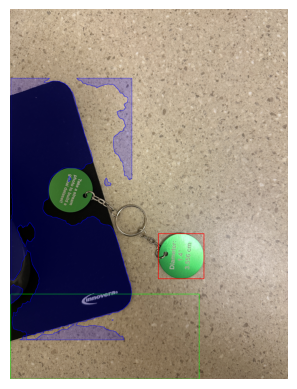

2/12: IMG_1628.JPG, resolution 0.11 mm/px (16.67%), 3.33 s
Detected 275 rocks, diagonal and count based D10, D50, D60, and D84 are: 1.92, 3.80, 4.00, and 4.64 cm
Detected 275 rocks, diagonal and area  based D10, D50, D60, and D84 are: 3.16, 4.32, 4.49, and 5.21 cm


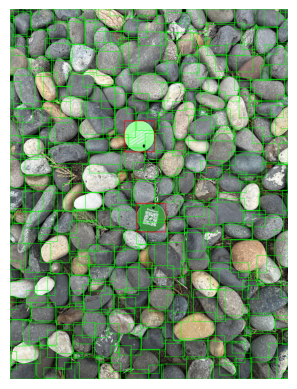

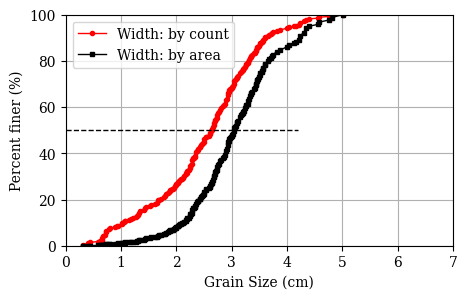

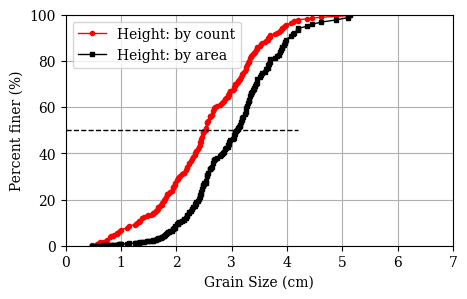

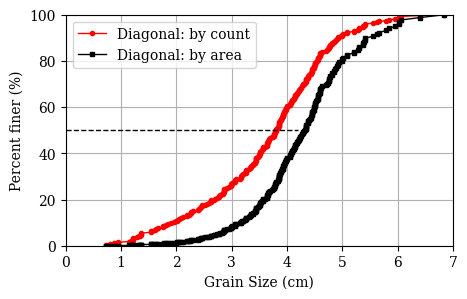

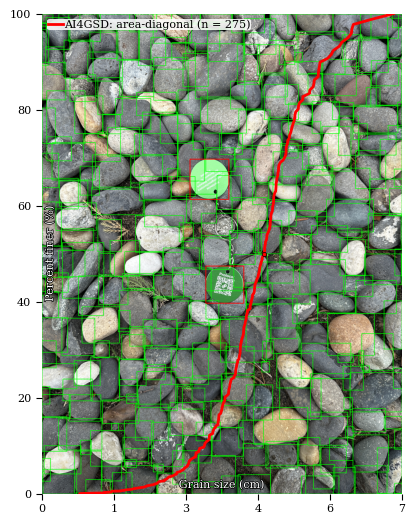

3/12: IMG_1629_60.png, resolution 0.13 mm/px (25.00%), 7.23 s
Detected 71 rocks, diagonal and count based D10, D50, D60, and D84 are: 1.44, 3.38, 3.63, and 4.28 cm
Detected 71 rocks, diagonal and area  based D10, D50, D60, and D84 are: 2.87, 3.89, 4.17, and 4.79 cm


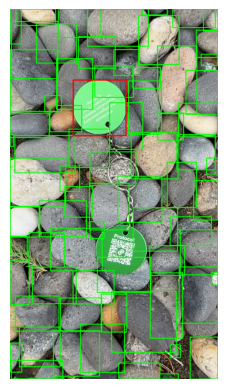

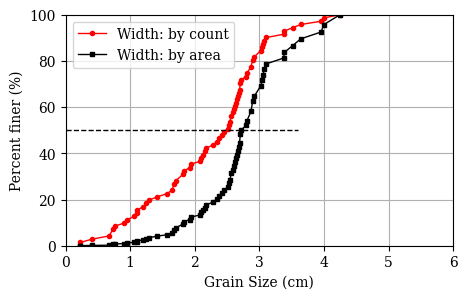

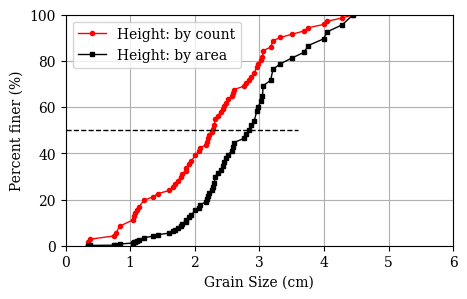

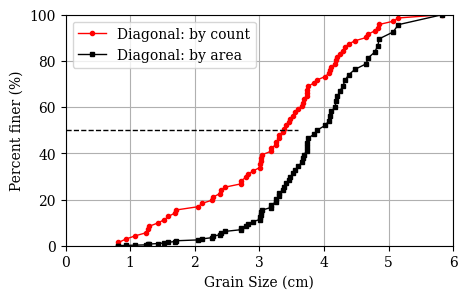

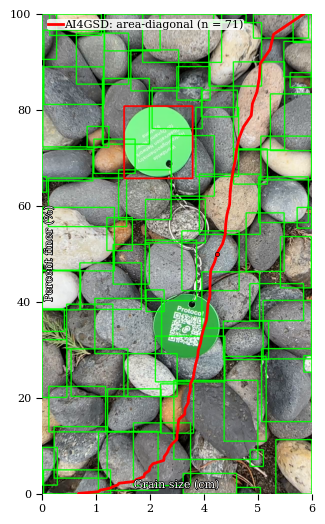

4/12: IMG_1629_120.png, resolution 0.31 mm/px (33.33%), 4.62 s
Detected 342 rocks, diagonal and count based D10, D50, D60, and D84 are: 1.94, 3.78, 4.04, and 4.68 cm
Detected 342 rocks, diagonal and area  based D10, D50, D60, and D84 are: 3.04, 4.29, 4.46, and 5.25 cm


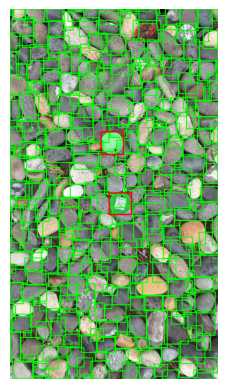

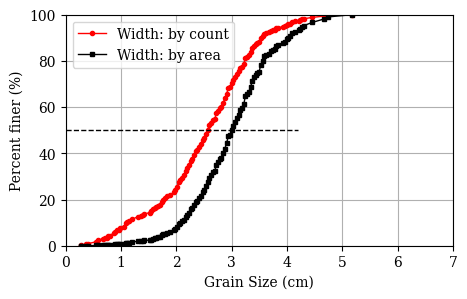

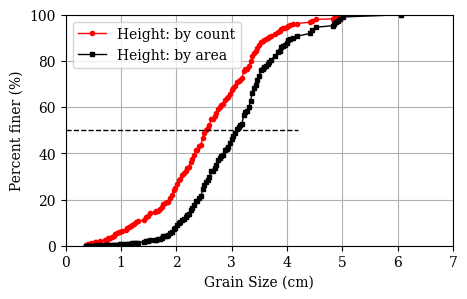

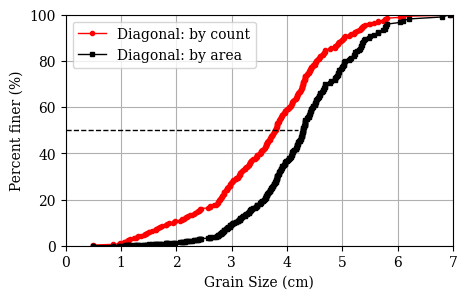

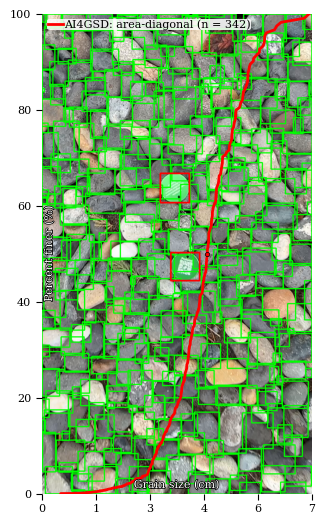

5/12: IMG_1629_180.png, resolution 0.47 mm/px (41.67%), 4.89 s
Detected 704 rocks, diagonal and count based D10, D50, D60, and D84 are: 2.25, 3.76, 3.97, and 4.74 cm
Detected 704 rocks, diagonal and area  based D10, D50, D60, and D84 are: 3.10, 4.26, 4.49, and 5.21 cm


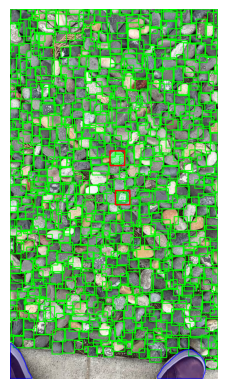

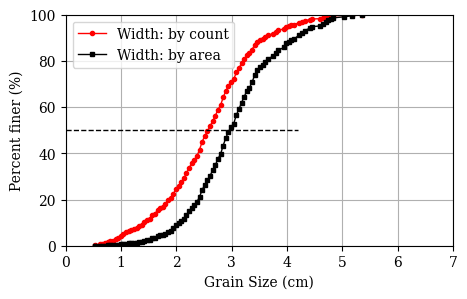

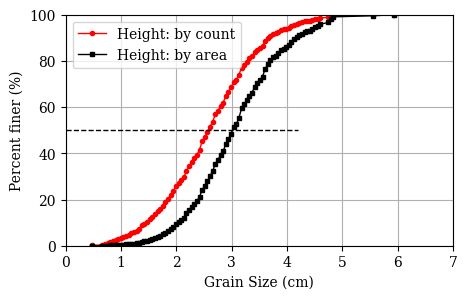

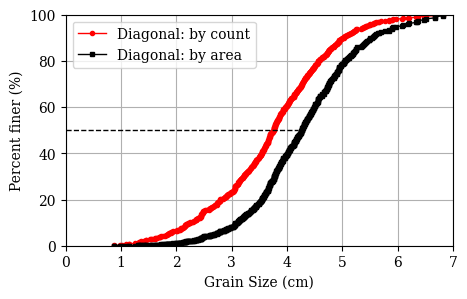

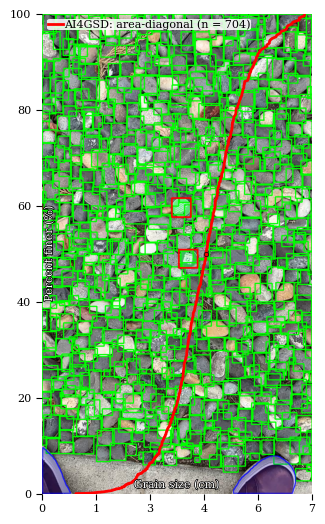

6/12: IMG_1629_240.png, resolution 0.55 mm/px (50.00%), 4.81 s
Detected 879 rocks, diagonal and count based D10, D50, D60, and D84 are: 2.36, 3.75, 3.99, and 4.74 cm
Detected 879 rocks, diagonal and area  based D10, D50, D60, and D84 are: 3.16, 4.32, 4.58, and 5.58 cm


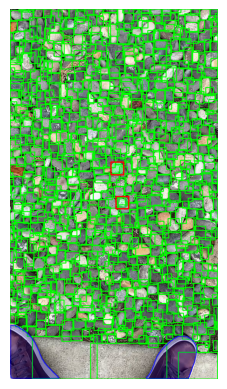

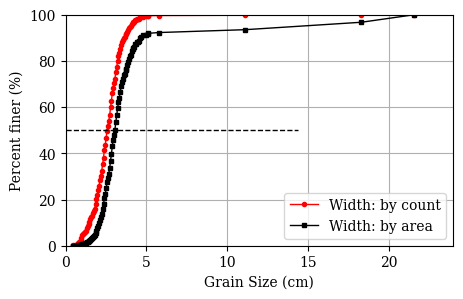

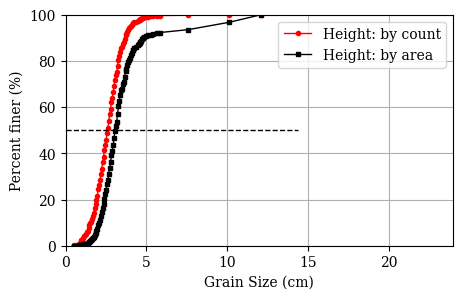

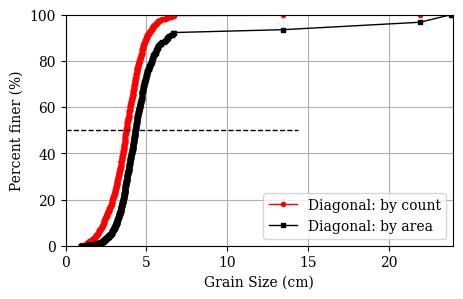

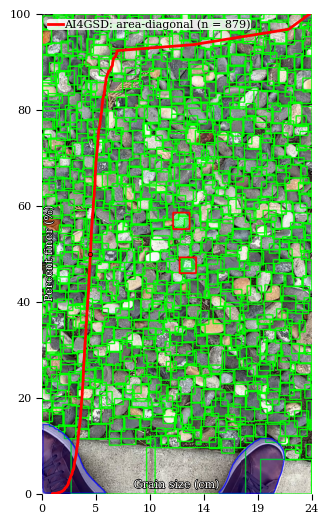

7/12: IMG_1629_300.png, resolution 0.57 mm/px (58.33%), 5.00 s
Detected 971 rocks, diagonal and count based D10, D50, D60, and D84 are: 2.43, 3.73, 3.97, and 4.68 cm
Detected 971 rocks, diagonal and area  based D10, D50, D60, and D84 are: 3.15, 4.25, 4.52, and 5.47 cm


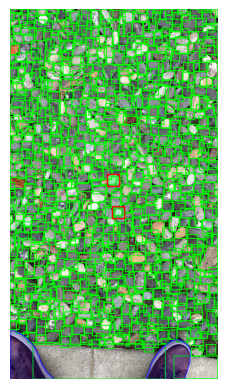

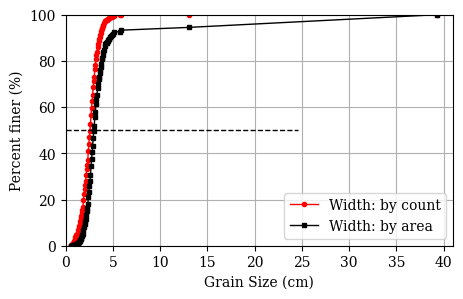

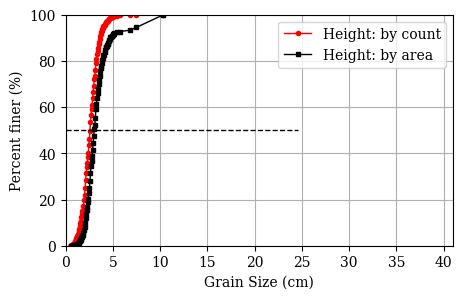

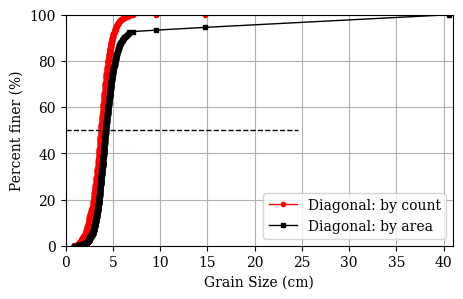

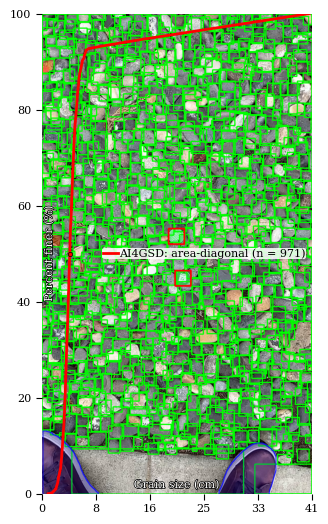

8/12: IMG_1629_360.png, resolution 0.59 mm/px (66.67%), 5.67 s
Detected 1032 rocks, diagonal and count based D10, D50, D60, and D84 are: 2.48, 3.74, 3.96, and 4.64 cm
Detected 1032 rocks, diagonal and area  based D10, D50, D60, and D84 are: 3.09, 4.16, 4.41, and 5.24 cm


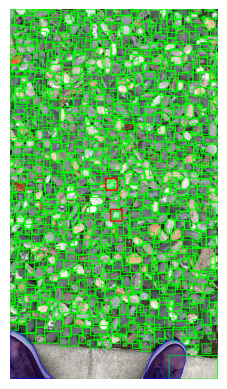

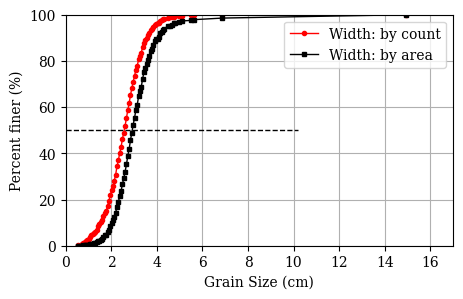

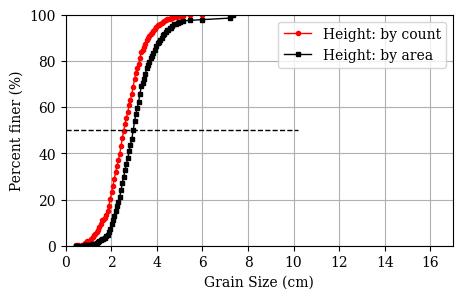

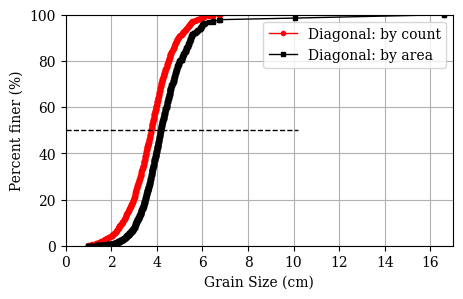

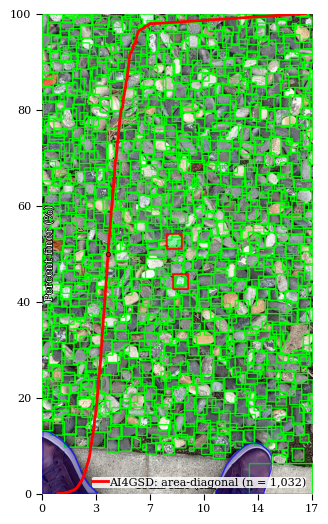

9/12: IMG_1630.JPG, resolution 0.10 mm/px (75.00%), 12.58 s
Detected 170 rocks, diagonal and count based D10, D50, D60, and D84 are: 1.19, 2.98, 3.53, and 4.51 cm
Detected 170 rocks, diagonal and area  based D10, D50, D60, and D84 are: 2.62, 4.36, 4.54, and 5.52 cm


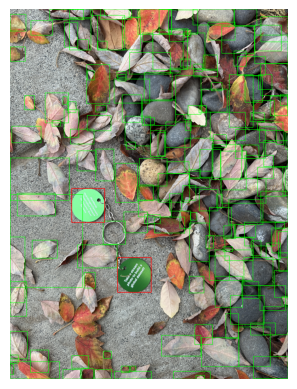

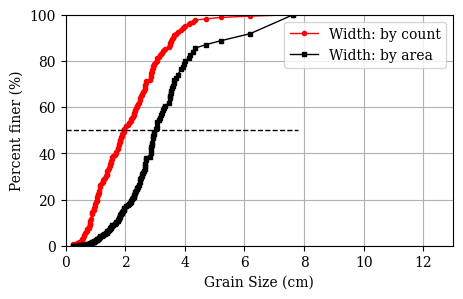

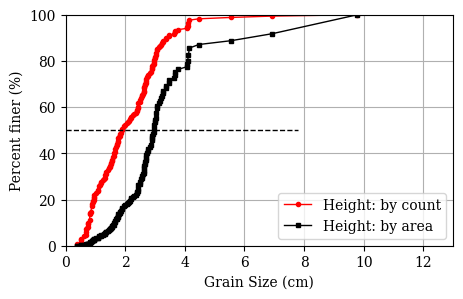

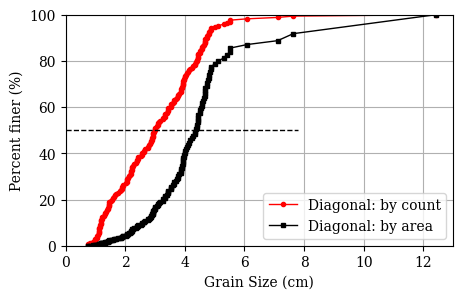

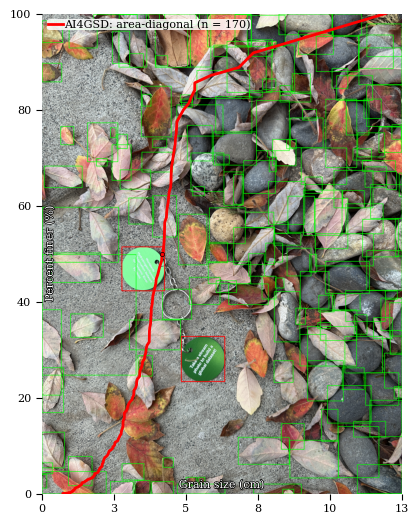

10/12: IMG_1631_60.png, resolution 0.19 mm/px (83.33%), 6.92 s
Detected 73 rocks, diagonal and count based D10, D50, D60, and D84 are: 1.21, 3.12, 3.59, and 4.49 cm
Detected 73 rocks, diagonal and area  based D10, D50, D60, and D84 are: 2.63, 4.47, 4.66, and 7.45 cm


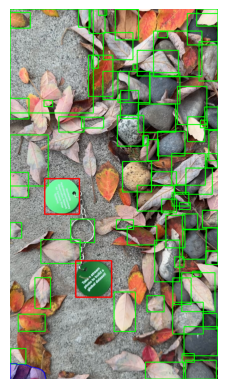

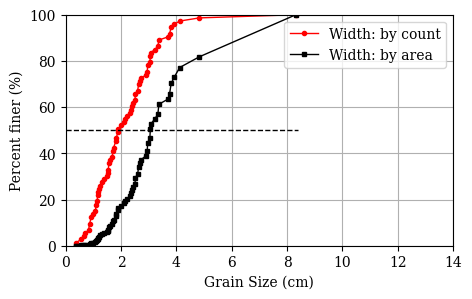

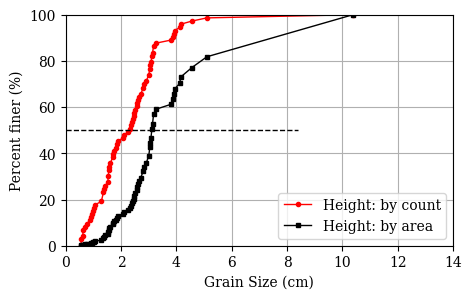

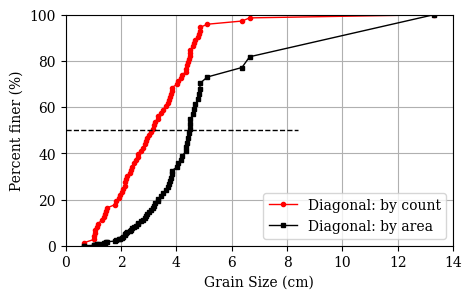

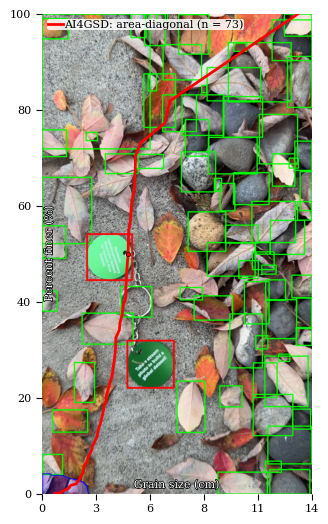

11/12: IMG_1631_120.png, resolution 0.43 mm/px (91.67%), 3.76 s
Detected 387 rocks, diagonal and count based D10, D50, D60, and D84 are: 1.77, 3.35, 3.69, and 4.61 cm
Detected 387 rocks, diagonal and area  based D10, D50, D60, and D84 are: 2.80, 4.52, 4.86, and 8.89 cm


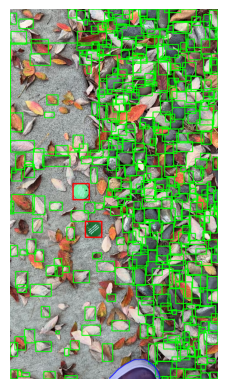

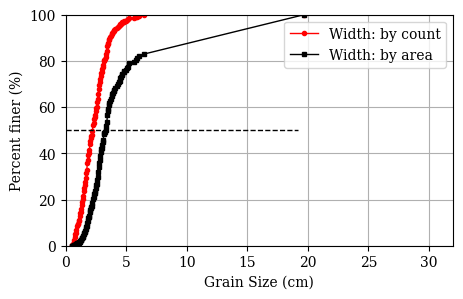

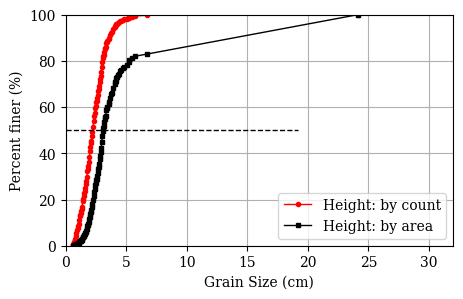

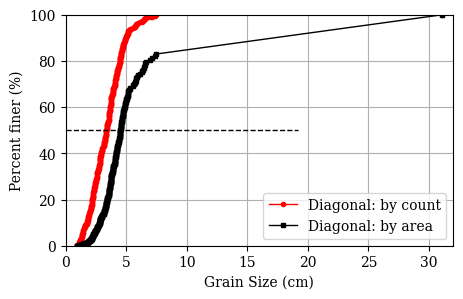

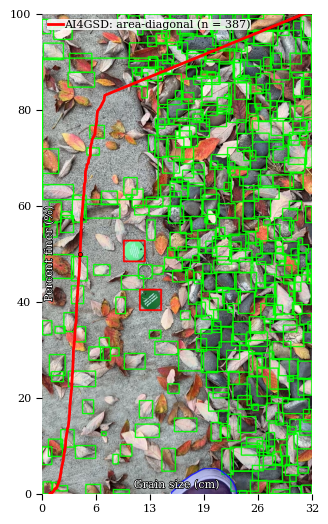

12/12: IMG_1631_180.png, resolution 0.55 mm/px (100.00%), 3.80 s
Detected 574 rocks, diagonal and count based D10, D50, D60, and D84 are: 2.03, 3.47, 3.77, and 4.69 cm
Detected 574 rocks, diagonal and area  based D10, D50, D60, and D84 are: 2.75, 4.27, 4.56, and 5.55 cm


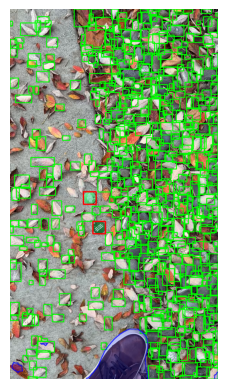

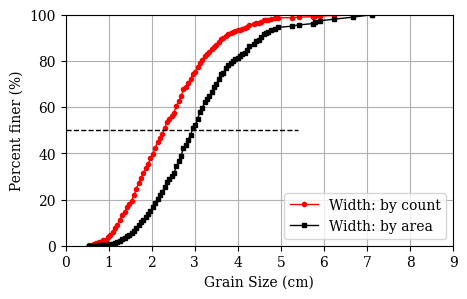

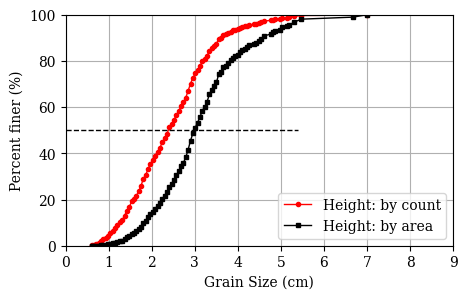

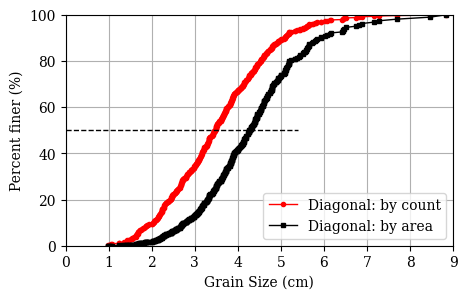

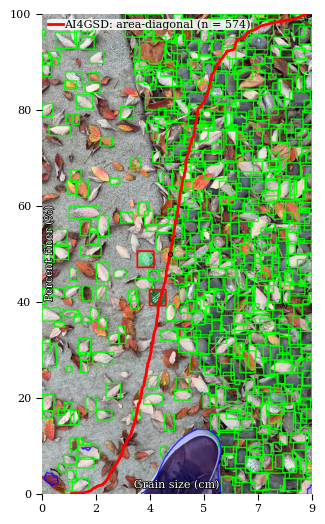

Output folder summary data to: /content/drive/MyDrive/20261113_YC_CSF/grains_predicts/20261113_YC_CSF_YOLO11m.1280.20250322_35/Statistics_V3_20261113_YC_CSF_YOLO11m.1280.20250322_35.csv
Total number of grains: 5479, number of grains per photo: 456.58
Total time: 67.73 s, time per photo 5.64 s

Output all summary data to: /content/drive/MyDrive/20261113_YC_CSF/Statistics_V3_20261113_YC_CSF_YOLO11m.1280.20250322_35.csv
Total execution time: 67.74 s


In [ ]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.ModelName = 'YOLO11m.1280.20250322'
PP.OverWriteAll = True
PP.YOLOSave = False
PP.SaveOverlayLabel = True
PP.PrintOnScreen = True
PP.OverlayFontSize = 4
PP.OverlayLegendFontSize = 4
PP.OverlayGSDTickLineWidth = 4
gsd = AI4GSD.Photo2GSD(PP)

### 7. Applying quality control

In [ ]:
gsdqc, stqc = AI4GSD.qualityControl(PhotoDir)


Quality control summary for 20261113_YC_CSF:
1/2: IMG_1629.MOV, time 6.6 s, area 2.7 m2, valid area 2.7 m2 (98.8%), frame 6, valid frame 5 (83.3%)
1/2: ***, grain number 3999, number per image 666.5; efficiency 0.4 m2/s, 608.2 grains/s
2/2: IMG_1631.MOV, time 3.9 s, area 1.1 m2, valid area 1.0 m2 (92.8%), frame 3, valid frame 2 (66.7%)
2/2: ***, grain number 1034, number per image 344.7; efficiency 0.3 m2/s, 268.3 grains/s
Videos: time 10.4 s, area 3.8 m2, valid area 3.7 m2 (97.1%), frame 9, valid frame 7 (77.8%)
Videos: grain number 5033, number per image 559.2; efficinecy 0.4 m2/s, 482.6 grains/s
Photos: time 231.0 s, area 0.3 m2, valid area 0.3 m2 (80.5%), frame 3, valid frame 2 (66.7%)
Photos: grain number 446, number per image 148.7; efficiency 0.0 m2/s, 1.9 grains/s
All: time 241.4 s, area 4.1 m2, valid area 3.9 m2 (95.8%), frame 12, valid frame 9 (75.0%)
All: grain number 5479, number per image 456.6; efficiency 0.0 m2/s, 22.7 grains/s


### 8. Data visualization

#### Metadata and pixel sizes for all images

In [ ]:
print(scales.head(10).T.to_string())

                                                                 0                    1                    2                    3                    4                    5                    6                    7                    8                    9
Name                                                  IMG_1627.JPG         IMG_1628.JPG      IMG_1629_60.png     IMG_1629_120.png     IMG_1629_180.png     IMG_1629_240.png     IMG_1629_300.png     IMG_1629_360.png         IMG_1630.JPG      IMG_1631_60.png
Folder                                             20261113_YC_CSF      20261113_YC_CSF      20261113_YC_CSF      20261113_YC_CSF      20261113_YC_CSF      20261113_YC_CSF      20261113_YC_CSF      20261113_YC_CSF      20261113_YC_CSF      20261113_YC_CSF
Scale_source                                              greencap             greencap             greencap             greencap             greencap             greencap             greencap             greencap             greenc

#### Grain size data before quality control

In [ ]:
print(gsd.head(10).T.to_string())

                                                                                      0                                         1                                         2                                         3                                         4                                         5                                         6                                         7                                         8                                         9
Name                                                                       IMG_1627.JPG                              IMG_1628.JPG                           IMG_1629_60.png                          IMG_1629_120.png                          IMG_1629_180.png                          IMG_1629_240.png                          IMG_1629_300.png                          IMG_1629_360.png                              IMG_1630.JPG                           IMG_1631_60.png
Folder                                                              

#### Grain size data after quality control

In [ ]:
print(gsdqc.head(10).T.to_string())

                                                                                      0                                         1                                         2                                         3                                         4                                         5                                         6                                         7                                         8
Name                                                                   IMG_1629_120.png                          IMG_1629_180.png                          IMG_1629_240.png                          IMG_1629_300.png                          IMG_1629_360.png                          IMG_1631_120.png                          IMG_1631_180.png                              IMG_1628.JPG                              IMG_1630.JPG
Folder                                                                  20261113_YC_CSF                           20261113_YC_CSF                       

#### Summary for each video

In [ ]:
print(stqc.head(10).T.to_string())

                                            0                1                2                3                4
Folder                        20261113_YC_CSF  20261113_YC_CSF  20261113_YC_CSF  20261113_YC_CSF  20261113_YC_CSF
Data_type                                 0.0              0.0              0.0              1.0              2.0
Video_ID                                  0.0              1.0          -9999.0          -9999.0          -9999.0
Video_name                             1629.0           1631.0          -9999.0          -9999.0          -9999.0
Frame_rate_fps                      59.923954        59.948097        59.936026          -9999.0          -9999.0
Width_px                               1080.0           1080.0           1080.0           3024.0           1566.0
Height_px                              1920.0           1920.0           1920.0           4032.0           2448.0
Dimension_megapixel                    2.0736           2.0736           2.0736        1